# Stock Price Analysis: AAPL vs. MSFT

This notebook explores daily market data for Apple (AAPL) and Microsoft (MSFT) from 2020 through 2025. It compares closing prices and trading volume, summarizes returns, and examines Apple moving-average crossover signals and their subsequent returns.

Run the notebook from top to bottom. The data-download cell requires an internet connection; the analysis uses the downloaded data in memory and does not save files.

In [ ]:
# Load the libraries used to fetch, organize, and visualize stock data.
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt

In [ ]:
# Set the symbols and date window used for the market-data download.
tickers = ['AAPL','MSFT']
Start, End = '2020-01-01', '2025-12-31'

In [ ]:
# Download both tickers together; yfinance returns fields such as Close and Volume.
# The commented loop shows an optional per-ticker CSV export workflow.
# for ticker in tickers:
#     data = yf.download(ticker, start=Start, end=End)
#     data.to_csv(f"{ticker}_data.csv")
data =yf.download(tickers, start='2020-01-01', end='2025-12-31')

[*********************100%***********************]  2 of 2 completed


In [ ]:
# Check a preview, column types, and dimensions of the downloaded DataFrame.
print(f"Data head:\n{data.head()}")
print(f"Data info:")
data.info()
print(f"Data shape: {data.shape}")

Data head:
Price           Close                   High                    Low  \
Ticker           AAPL        MSFT       AAPL        MSFT       AAPL   
Date                                                                  
2020-01-02  72.271561  151.544250  72.331717  151.648036  71.029938   
2020-01-03  71.568932  149.657288  72.326897  150.912139  71.345153   
2020-01-06  72.139198  150.044113  72.177699  150.110165  70.442799   
2020-01-07  71.799904  148.676056  72.403866  150.647958  71.580935   
2020-01-08  72.954895  151.044235  73.255675  151.714124  71.503931   

Price                        Open                 Volume            
Ticker            MSFT       AAPL        MSFT       AAPL      MSFT  
Date                                                                
2020-01-02  149.383652  71.282590  149.808222  135480400  22622100  
2020-01-03  149.128932  71.501557  149.374250  146322800  21116200  
2020-01-06  147.666500  70.693051  148.204300  118387200  20813700  
2020-0

In [ ]:
# Demonstrate selecting one ticker from the downloaded field/ticker columns.
print(data['Close'].AAPL)
print(data['Volume'].MSFT)
print(f"Last 5 rows: {data.tail(5)}")
# Calculate the average closing price for each ticker.
avg_close=data["Close"].mean()
print(f"Average closing price: {avg_close}")

Date
2020-01-02     72.271561
2020-01-03     71.568932
2020-01-06     72.139198
2020-01-07     71.799904
2020-01-08     72.954895
                 ...    
2025-12-23    271.620667
2025-12-24    273.066711
2025-12-26    272.657867
2025-12-29    273.016876
2025-12-30    272.338684
Name: AAPL, Length: 1507, dtype: float64
Date
2020-01-02    22622100
2020-01-03    21116200
2020-01-06    20813700
2020-01-07    21634100
2020-01-08    27746500
                ...   
2025-12-23    14683600
2025-12-24     5855900
2025-12-26     8842200
2025-12-29    10893400
2025-12-30    13944500
Name: MSFT, Length: 1507, dtype: int64
Last 5 rows: Price            Close                    High                     Low  \
Ticker            AAPL        MSFT        AAPL        MSFT        AAPL   
Date                                                                     
2025-12-23  271.620667  483.780823  271.760301  484.754625  268.828279   
2025-12-24  273.066711  484.943420  274.682309  486.076248  271.461097   

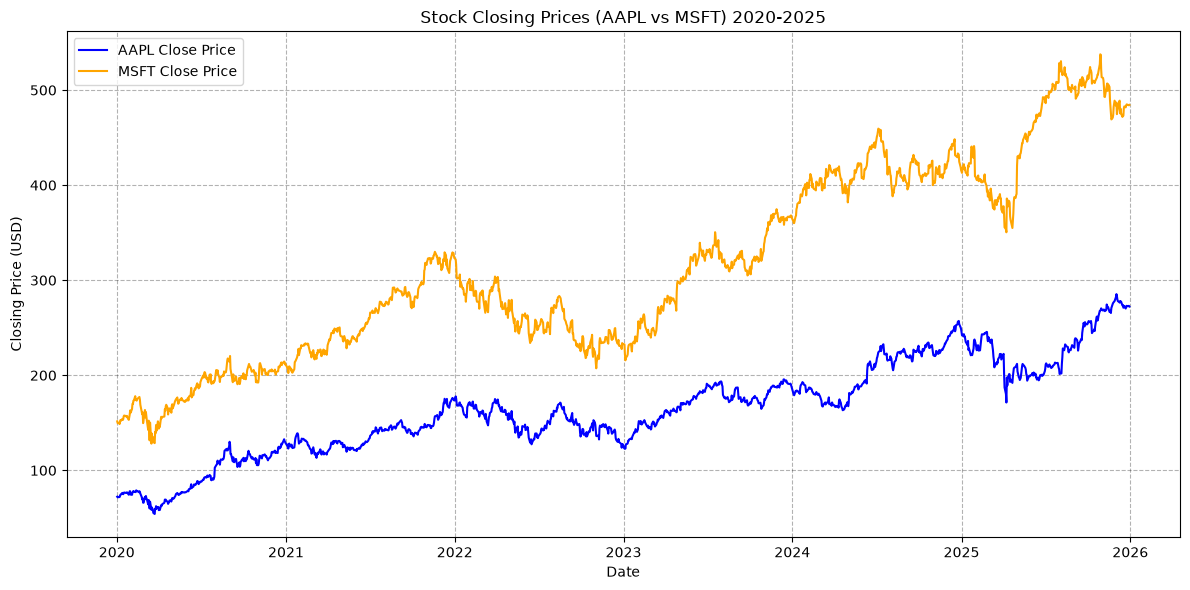

In [ ]:
# Compare daily closing prices for Apple and Microsoft over the full date range.
plt.figure(figsize=(12,6))
plt.plot(data.index, data['Close']['AAPL'], label='AAPL Close Price', color='blue')
plt.plot(data.index, data['Close']['MSFT'], label='MSFT Close Price', color='orange')
plt.title('Stock Closing Prices (AAPL vs MSFT) 2020-2025')
plt.xlabel('Date')
plt.ylabel('Closing Price (USD)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.3, color='black')
plt.tight_layout()
plt.show()

In [ ]:
# Inspect the date index and the field/ticker column structure used above.
print(data.index)
print(data.columns)
print(data.index.name)

DatetimeIndex(['2020-01-02', '2020-01-03', '2020-01-06', '2020-01-07',
               '2020-01-08', '2020-01-09', '2020-01-10', '2020-01-13',
               '2020-01-14', '2020-01-15',
               ...
               '2025-12-16', '2025-12-17', '2025-12-18', '2025-12-19',
               '2025-12-22', '2025-12-23', '2025-12-24', '2025-12-26',
               '2025-12-29', '2025-12-30'],
              dtype='datetime64[s]', name='Date', length=1507, freq=None)
MultiIndex([( 'Close', 'AAPL'),
            ( 'Close', 'MSFT'),
            (  'High', 'AAPL'),
            (  'High', 'MSFT'),
            (   'Low', 'AAPL'),
            (   'Low', 'MSFT'),
            (  'Open', 'AAPL'),
            (  'Open', 'MSFT'),
            ('Volume', 'AAPL'),
            ('Volume', 'MSFT')],
           names=['Price', 'Ticker'])
Date


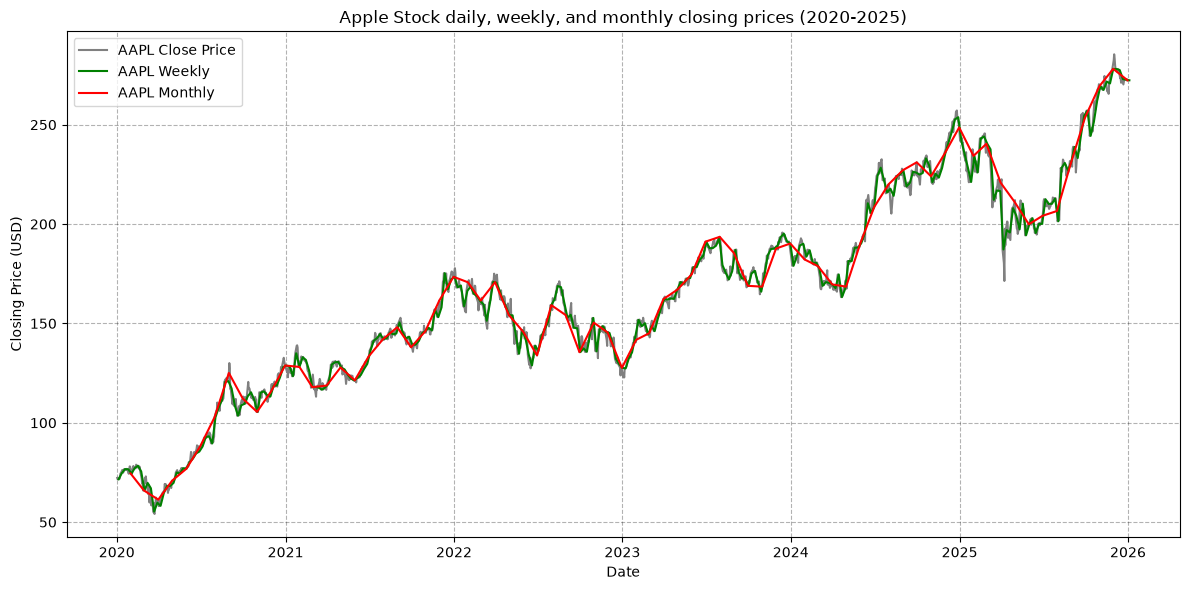

In [ ]:
# Resample daily closing prices to weekly and month-end observations.
appl_weekly = data['Close']['AAPL'].resample('W').last()
msft_weekly = data['Close']['MSFT'].resample('W').last()
appl_monthly = data['Close']['AAPL'].resample('ME').last()
msft_monthly = data['Close']['MSFT'].resample('ME').last()


# Overlay Apple's daily, weekly, and month-end closing prices.
plt.figure(figsize=(12,6))
plt.plot(data.index, data['Close']['AAPL'], label='AAPL Close Price', color='grey')
plt.plot(appl_weekly.index, appl_weekly, label='AAPL Weekly', color='green')
plt.plot(appl_monthly.index, appl_monthly, label='AAPL Monthly', color='red')
plt.title('Apple Stock daily, weekly, and monthly closing prices (2020-2025)')
plt.xlabel('Date')
plt.ylabel('Closing Price (USD)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.3, color='black')
plt.tight_layout()
plt.show()

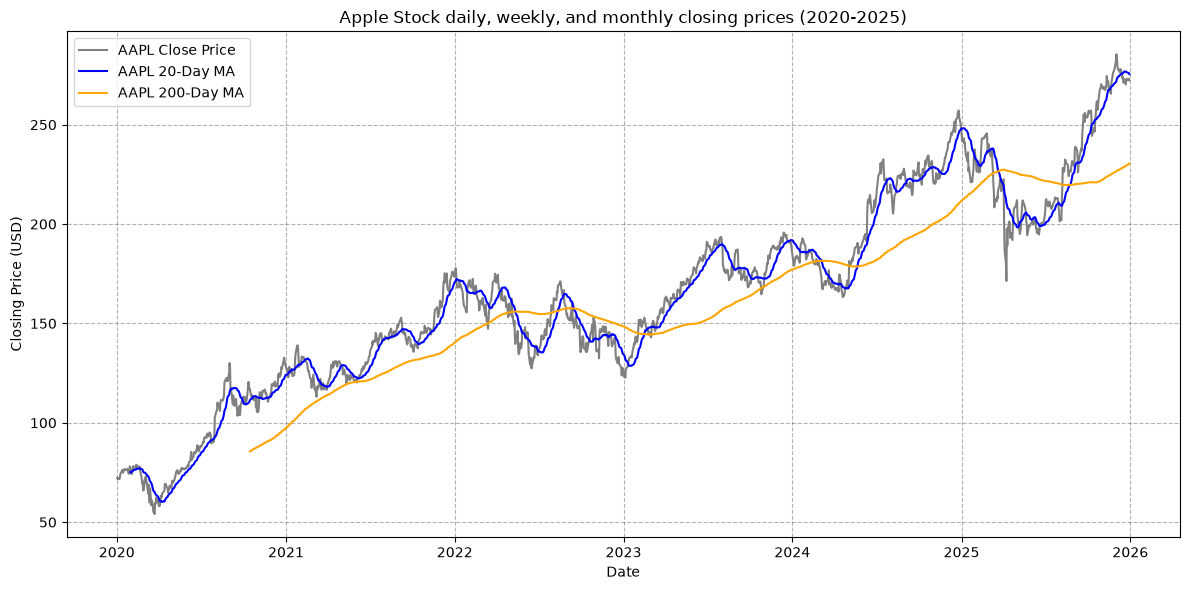

In [ ]:
# Calculate Apple's 20-session and 200-session simple moving averages.
appl_ma20 = data['Close']['AAPL'].rolling(window=20).mean()
appl_ma200 = data['Close']['AAPL'].rolling(window=200).mean()


# Plot the closing price alongside both moving averages.
plt.figure(figsize=(12,6))
plt.plot(data.index, data['Close']['AAPL'], label='AAPL Close Price', color='grey')
plt.plot(appl_ma20.index, appl_ma20, label='AAPL 20-Day MA', color='blue')
plt.plot(appl_ma200.index, appl_ma200, label='AAPL 200-Day MA', color='orange')
plt.title('Apple Stock daily, weekly, and monthly closing prices (2020-2025)')
plt.xlabel('Date')
plt.ylabel('Closing Price (USD)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.3, color='black')
plt.tight_layout()
plt.show()




In [ ]:
# Mark crossovers only when the relationship between the averages changes today.
# A golden cross is MA20 moving above MA200; a death cross is the reverse.
golden_cross = ( (appl_ma20.shift(1) < appl_ma200.shift(1)) & (appl_ma20 > appl_ma200) )
print(f"Golden Cross:")
print(f"{golden_cross[golden_cross].index}")

death_cross = ( (appl_ma20.shift(1) > appl_ma200.shift(1)) & (appl_ma20 < appl_ma200) )
print(f"Death Cross:")
print(f"{death_cross[death_cross].index}")

Golden Cross:
DatetimeIndex(['2022-08-12', '2023-02-15', '2024-05-21', '2025-08-25'],
              dtype='datetime64[s]', name='Date', freq=None)
Death Cross:
DatetimeIndex(['2022-05-12', '2022-09-16', '2024-03-05', '2025-03-24'],
              dtype='datetime64[s]', name='Date', freq=None)


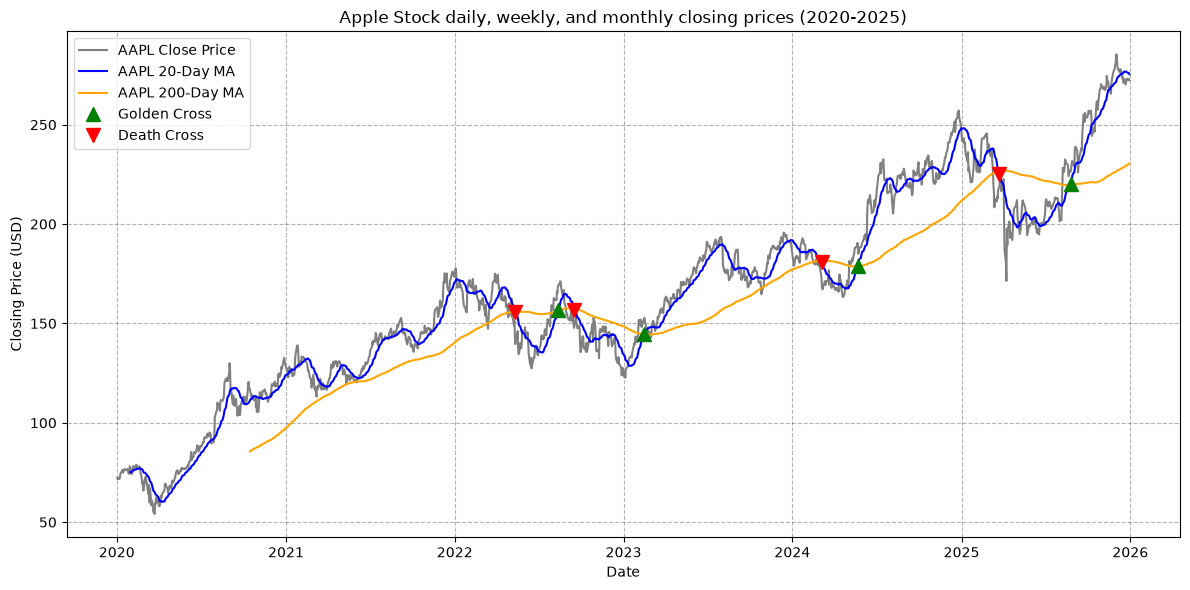

In [ ]:
# Show the moving averages and annotate the dates where they cross.
plt.figure(figsize=(12,6))
plt.plot(data.index, data['Close']['AAPL'], label='AAPL Close Price', color='grey')
plt.plot(appl_ma20.index, appl_ma20, label='AAPL 20-Day MA', color='blue')
plt.plot(appl_ma200.index, appl_ma200, label='AAPL 200-Day MA', color='orange')
plt.plot(golden_cross[golden_cross].index, appl_ma20[golden_cross],label='Golden Cross', color='green', marker='^', markersize=10, linestyle='None')
plt.plot(death_cross[death_cross].index, appl_ma20[death_cross],label='Death Cross', color='red', marker='v', markersize=10, linestyle='None')
plt.title('Apple Stock daily, weekly, and monthly closing prices (2020-2025)')
plt.xlabel('Date')
plt.ylabel('Closing Price (USD)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.3, color='black')
plt.tight_layout()
plt.show()

In [ ]:
# Assemble Apple's prices, moving averages, and Boolean crossover flags.
table_data= pd.DataFrame({
    'Close': data['Close']['AAPL'],
    'MA20': appl_ma20,
    'MA200': appl_ma200
})
table_data['Golden Cross'] = golden_cross
table_data['Death Cross'] = death_cross
# Keep rows where either crossover signal is true.
crossovers = table_data[table_data['Golden Cross'] | table_data['Death Cross']]
print(crossovers)
print(table_data['Golden Cross'].sum())
print(table_data['Death Cross'].sum())

                 Close        MA20       MA200  Golden Cross  Death Cross
Date                                                                     
2022-05-12  139.634109  155.752061  155.969559         False         True
2022-08-12  168.801987  156.793375  156.369243          True        False
2022-09-16  147.812057  156.774482  157.437455         False         True
2023-02-15  152.839111  144.916671  144.638685          True        False
2024-03-05  168.285385  180.990768  181.533185         False         True
2024-05-21  190.533768  179.087527  178.656201          True        False
2025-03-24  219.380630  225.321099  226.689239         False         True
2025-08-25  226.323959  220.128202  219.723689          True        False
4
4


In [ ]:
# Compute percentage changes at daily, weekly, month-end, and year-end intervals.
daily_returns  = data['Close'].pct_change() * 100
weekly_returns = data['Close'].resample('W').last().pct_change() * 100
monthly_returns = data['Close'].resample('ME').last().pct_change() * 100
yearly_returns = data['Close'].resample('YE').last().pct_change() * 100


# Format the first few observations for readable display (including missing values).
def format_returns(returns):
    return returns.head().map(lambda x: f'{x:.2f}%')


# Preview each return frequency.
print('Daily Returns:')
print(format_returns(daily_returns))
print('Weekly Returns:')
print(format_returns(weekly_returns))

print('Monthly Returns:')
print(format_returns(monthly_returns))

print('Yearly Returns:')
print(format_returns(yearly_returns))

Daily Returns:
Ticker        AAPL    MSFT
Date                      
2020-01-02    nan%    nan%
2020-01-03  -0.97%  -1.25%
2020-01-06   0.80%   0.26%
2020-01-07  -0.47%  -0.91%
2020-01-08   1.61%   1.59%
Weekly Returns:
Ticker        AAPL    MSFT
Date                      
2020-01-05    nan%    nan%
2020-01-12   4.34%   1.71%
2020-01-19   2.71%   3.57%
2020-01-26  -0.13%  -1.23%
2020-02-02  -2.76%   3.14%
Monthly Returns:
Ticker         AAPL    MSFT
Date                       
2020-01-31     nan%    nan%
2020-02-29  -11.47%  -4.57%
2020-03-31   -6.98%  -2.65%
2020-04-30   15.54%  13.63%
2020-05-31    8.51%   2.54%
Yearly Returns:
Ticker         AAPL     MSFT
Date                        
2020-12-31     nan%     nan%
2021-12-31   34.65%   52.48%
2022-12-31  -26.40%  -28.02%
2023-12-31   49.01%   58.19%
2024-12-31   30.71%   12.93%


In [ ]:
# Average the percentage returns at each sampling frequency for both tickers.
average_daily_returns = daily_returns.mean()
average_weekly_returns = weekly_returns.mean()
average_monthly_returns = monthly_returns.mean()
average_yearly_returns = yearly_returns.mean()

# Display averages using the same percentage formatting helper.
print(f"Average Daily Returns: ")
print(format_returns(average_daily_returns))
print(f"Average Weekly Returns: ")
print(format_returns(average_weekly_returns))
print(f"Average Monthly Returns: ")
print(format_returns(average_monthly_returns))
print(f"Average Yearly Returns: ")
print(format_returns(average_yearly_returns))

Average Daily Returns: 
Ticker
AAPL    0.11%
MSFT    0.09%
dtype: str
Average Weekly Returns: 
Ticker
AAPL    0.51%
MSFT    0.44%
dtype: str
Average Monthly Returns: 
Ticker
AAPL    2.16%
MSFT    1.77%
dtype: str
Average Yearly Returns: 
Ticker
AAPL    19.50%
MSFT    22.42%
dtype: str


In [ ]:
# Summarize the distribution of daily percentage returns for each ticker.
print(daily_returns.describe())

Ticker         AAPL         MSFT
count   1506.000000  1506.000000
mean       0.108142     0.094502
std        2.004425     1.861782
min      -12.864686   -14.739052
25%       -0.821224    -0.789805
50%        0.114019     0.111023
75%        1.147112     1.043534
max       15.328862    14.216923


In [ ]:
# Compare average, best, worst, and standard-deviation daily returns by ticker.
stock_stats = pd.DataFrame({
    'Average Return': daily_returns.mean(),
    'Highest Return': daily_returns.max(),
    'Lowest Return': daily_returns.min(),
    'Volatility (Std)': daily_returns.std()
})

# Format all summary values as percentages for display.
print(stock_stats.map(lambda x: f'{x:.2f}%'))

       Average Return Highest Return Lowest Return Volatility (Std)
Ticker                                                             
AAPL            0.11%         15.33%       -12.86%            2.00%
MSFT            0.09%         14.22%       -14.74%            1.86%


In [ ]:
# Select Apple's close series and calculate returns 30, 60, and 90 trading rows ahead.
# The final rows will be NaN where the requested future price is unavailable.
aapl_close = data['Close']['AAPL']

# Calculate future returns
return_30d = (aapl_close.shift(-30) / aapl_close - 1) * 100
return_60d = (aapl_close.shift(-60) / aapl_close - 1) * 100
return_90d = (aapl_close.shift(-90) / aapl_close - 1) * 100

In [ ]:
# Align Apple's price, future returns, and crossover flags by date for analysis.
crossover_analysis = pd.DataFrame({
    'Close': aapl_close,
    'Return 30d': return_30d,
    'Return 60d': return_60d,
    'Return 90d': return_90d,
    'Golden Cross': golden_cross,
    'Death Cross': death_cross
})

In [ ]:
# Split the combined table into the observations for each signal type.
golden_results = crossover_analysis[
    crossover_analysis['Golden Cross']
]

death_results = crossover_analysis[
    crossover_analysis['Death Cross']
]

In [ ]:
# Compare mean future returns after golden-cross and death-cross dates.
print("Golden Cross Performance:")
print(golden_results[['Return 30d', 'Return 60d', 'Return 90d']].mean())

print("\nDeath Cross Performance:")
print(death_results[['Return 30d', 'Return 60d', 'Return 90d']].mean())

Golden Cross Performance:
Return 30d    5.677496
Return 60d    6.902338
Return 90d    6.504570
dtype: float64

Death Cross Performance:
Return 30d   -2.149903
Return 60d    3.414041
Return 90d    8.360759
dtype: float64


In [ ]:
# Build one row per crossover signal with its starting price and forward returns.
def evaluate_crossovers(table_data):
    results = []

    close = table_data['Close']

    for signal in ['Golden Cross', 'Death Cross']:

        signal_dates = table_data.index[table_data[signal]]

        for date in signal_dates:

            starting_price = close.loc[date]

            result = {
                'Date': date,
                'Signal': signal,
                'Starting Price': starting_price
            }

            for days in [30, 60, 90]:

                future_price = close.shift(-days).loc[date]

                future_return = (
                    (future_price / starting_price) - 1
                ) * 100

                result[f'{days}-Day Return'] = future_return

            results.append(result)

    return pd.DataFrame(results)

In [ ]:
# Run the event-level analysis and display returns rounded to two decimals.
crossover_results = evaluate_crossovers(table_data)

print(crossover_results.round(2))

        Date        Signal  Starting Price  30-Day Return  60-Day Return  \
0 2022-08-12  Golden Cross          168.80         -12.39         -19.15   
1 2023-02-15  Golden Cross          152.84           4.53          11.25   
2 2024-05-21  Golden Cross          190.53          17.67          17.66   
3 2025-08-25  Golden Cross          226.32          12.91          17.85   
4 2022-05-12   Death Cross          139.63          -0.63          15.85   
5 2022-09-16   Death Cross          147.81           3.34          -3.96   
6 2024-03-05   Death Cross          168.29          -1.25          12.60   
7 2025-03-24   Death Cross          219.38         -10.07         -10.82   

   90-Day Return  
0         -23.00  
1          21.24  
2          21.27  
3            NaN  
4           7.98  
5          -4.31  
6          37.97  
7          -8.19  


/tmp/ipykernel_32382/2144674689.py:3: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  print(crossover_results.round(2))


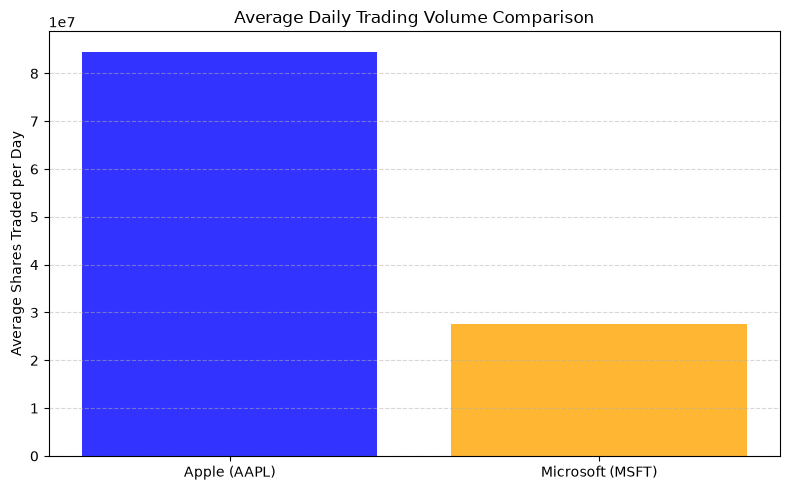

In [ ]:
# Compare mean daily share volume; select Volume before selecting each ticker.
plt.figure(figsize=(8, 5))
plt.bar(
    ["Apple (AAPL)", "Microsoft (MSFT)"],
    [data["Volume"]["AAPL"].mean(), data["Volume"]["MSFT"].mean()],
    color=["blue", "orange"],
    alpha=0.8,
)
plt.title("Average Daily Trading Volume Comparison")
plt.ylabel("Average Shares Traded per Day")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()